
# SwiftLog Logistics Analytics & AI Transformation — Week 5
## Data Science Track — Mission DS05: Supply Chain Intelligence & Feature Engineering for Predictive Logistics

**Intern:** Takudzwa Jeffrey Gumbo (TJ)  
**Programme:** AnalystLab Africa Experience Lab, Batch E

### Purpose
This self-contained notebook integrates, cleans and analyses the supplied SwiftLog logistics datasets; performs comprehensive EDA and statistical testing; engineers features for future predictive modelling; discovers exploratory customer, product and warehouse segments; and exports a machine-learning-ready analytical dataset.

### Responsible analytical commitments
- No supplier-to-product or supplier-to-shipment relationship is fabricated because no `SupplierID` exists outside the standalone Suppliers table.
- Warehouse capacity is not supplied; any warehouse utilisation concept is labelled as a **proxy**, not a true utilisation rate.
- Repeated Warehouse–Product inventory rows are treated as stock movements and retained, following AnalystLab guidance.
- Product returns are recorded at **order level**, not product-item level. Product/category return metrics are therefore labelled **returned-order exposure**, not true product return rates.
- Inferred business rules are identified explicitly rather than presented as supplied definitions.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings, json, html, shutil
warnings.filterwarnings('ignore')

SEED = 42
FILES = [
    'SwiftLog_Customers.csv','SwiftLog_Orders.csv','SwiftLog_Order_Items.csv','SwiftLog_Products.csv',
    'SwiftLog_Suppliers.csv','SwiftLog_Warehouses.csv','SwiftLog_Inventory.csv','SwiftLog_Shipments.csv',
    'SwiftLog_Delivery_Performance.csv','SwiftLog_Employees.csv','SwiftLog_Returns.csv',
    'SwiftLog_Data_Dictionary.csv'
]

# Colab: use the user's normal Analyst Lab Africa Drive mount and search recursively.
if Path('/content').exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        SEARCH_ROOT = Path('/content/drive/MyDrive/Analyst Lab Africa')
        OUTPUT_ROOT = SEARCH_ROOT / 'SwiftLog Week 5 (TJ Gumbo)'
    except Exception:
        SEARCH_ROOT = Path.cwd()
        OUTPUT_ROOT = Path.cwd() / 'SwiftLog_Week5_Output'
else:
    SEARCH_ROOT = Path('/mnt/data')
    OUTPUT_ROOT = Path('/mnt/data/Week5_DataScience_SwiftLog_TakudzwaGumbo_FINAL')

for d in ['Data/Cleaned_Datasets','Visualizations/Charts','Analysis','Reports']:
    (OUTPUT_ROOT/d).mkdir(parents=True, exist_ok=True)

def find_file(name: str) -> Path:
    direct = SEARCH_ROOT / name
    if direct.exists():
        return direct
    matches = list(SEARCH_ROOT.rglob(name))
    if not matches:
        raise FileNotFoundError(f'Missing {name} under {SEARCH_ROOT}')
    return matches[0]

PATHS = {name: find_file(name) for name in FILES}
print('Data search root:', SEARCH_ROOT)
print('Output root:', OUTPUT_ROOT)
for name,path in PATHS.items():
    print(f'{name}: {path}')


Mounted at /content/drive
Data search root: /content/drive/MyDrive/Analyst Lab Africa
Output root: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5 (TJ Gumbo)
SwiftLog_Customers.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Customers.csv
SwiftLog_Orders.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Orders.csv
SwiftLog_Order_Items.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Order_Items.csv
SwiftLog_Products.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Products.csv
SwiftLog_Suppliers.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Suppliers.csv
SwiftLog_Warehouses.csv: /content/drive/MyDrive/Analyst Lab Africa/SwiftLog Week 5/Data/Original Datasets/SwiftLog_Warehouses.csv
SwiftLog_Inventory.csv: /content/drive/MyDrive/Analyst Lab Africa/


## Part 1 — Data Acquisition & Understanding
All supplied datasets are loaded before transformation. The checks below record table size, missingness, duplicate rows, keys and referential integrity. This step also identifies incomplete relationships in both directions; a foreign key can be valid while some parent records still have no child records.


In [2]:

tables = {Path(n).stem.replace('SwiftLog_',''): pd.read_csv(p) for n,p in PATHS.items()}
for name,df in tables.items():
    for c in df.select_dtypes(include='object').columns:
        df[c] = df[c].astype(str).str.strip()

profile=[]
for name,df in tables.items():
    profile.append({
        'Dataset':name,'Rows':len(df),'Columns':df.shape[1],
        'MissingCells':int(df.isna().sum().sum()),
        'ExactDuplicateRows':int(df.duplicated().sum())
    })
profile_df=pd.DataFrame(profile).sort_values('Dataset').reset_index(drop=True)
display(profile_df)

print('\nKey coverage findings:')
orders_without_items = set(tables['Orders'].OrderID) - set(tables['Order_Items'].OrderID)
print('Orders without Order_Items:', len(orders_without_items))
print('Unique orders represented in Order_Items:', tables['Order_Items'].OrderID.nunique())
print('Returns rows / unique returned orders:', len(tables['Returns']), '/', tables['Returns'].OrderID.nunique())
print('Repeated Warehouse-Product inventory rows beyond first occurrence:',
      tables['Inventory'].duplicated(['WarehouseID','ProductID']).sum())
print('Exact repeated inventory rows:', tables['Inventory'].duplicated().sum())


,Dataset,Rows,Columns,MissingCells,ExactDuplicateRows
0,Customers,1000,3,0,0
1,Data_Dictionary,11,2,0,0
2,Delivery_Performance,5000,3,0,0
3,Employees,200,2,0,0
4,Inventory,4000,3,0,3
5,Order_Items,15000,4,0,0
6,Orders,5000,4,0,0
7,Products,250,3,0,0
8,Returns,500,3,0,0
9,Shipments,5000,4,0,0



Key coverage findings:
Orders without Order_Items: 236
Unique orders represented in Order_Items: 4764
Returns rows / unique returned orders: 500 / 473
Repeated Warehouse-Product inventory rows beyond first occurrence: 1545
Exact repeated inventory rows: 3


In [3]:

def unmatched(child, ccol, parent, pcol):
    return int((~child[ccol].isin(parent[pcol])).sum())
relationships = [
    ('Orders.CustomerID → Customers.CustomerID', unmatched(tables['Orders'],'CustomerID',tables['Customers'],'CustomerID')),
    ('Order_Items.OrderID → Orders.OrderID', unmatched(tables['Order_Items'],'OrderID',tables['Orders'],'OrderID')),
    ('Order_Items.ProductID → Products.ProductID', unmatched(tables['Order_Items'],'ProductID',tables['Products'],'ProductID')),
    ('Shipments.OrderID → Orders.OrderID', unmatched(tables['Shipments'],'OrderID',tables['Orders'],'OrderID')),
    ('Shipments.WarehouseID → Warehouses.WarehouseID', unmatched(tables['Shipments'],'WarehouseID',tables['Warehouses'],'WarehouseID')),
    ('Delivery_Performance.ShipmentID → Shipments.ShipmentID', unmatched(tables['Delivery_Performance'],'ShipmentID',tables['Shipments'],'ShipmentID')),
    ('Inventory.ProductID → Products.ProductID', unmatched(tables['Inventory'],'ProductID',tables['Products'],'ProductID')),
    ('Inventory.WarehouseID → Warehouses.WarehouseID', unmatched(tables['Inventory'],'WarehouseID',tables['Warehouses'],'WarehouseID')),
    ('Employees.WarehouseID → Warehouses.WarehouseID', unmatched(tables['Employees'],'WarehouseID',tables['Warehouses'],'WarehouseID')),
    ('Returns.OrderID → Orders.OrderID', unmatched(tables['Returns'],'OrderID',tables['Orders'],'OrderID')),
]
relationship_checks = pd.DataFrame(relationships,columns=['Relationship','UnmatchedRows'])
display(relationship_checks)
assert relationship_checks.UnmatchedRows.eq(0).all()
print('All linkable foreign keys resolve with zero unmatched child records.')


,Relationship,UnmatchedRows
0,Orders.CustomerID → Customers.CustomerID,0
1,Order_Items.OrderID → Orders.OrderID,0
2,Order_Items.ProductID → Products.ProductID,0
3,Shipments.OrderID → Orders.OrderID,0
4,Shipments.WarehouseID → Warehouses.WarehouseID,0
5,Delivery_Performance.ShipmentID → Shipments.Sh...,0
6,Inventory.ProductID → Products.ProductID,0
7,Inventory.WarehouseID → Warehouses.WarehouseID,0
8,Employees.WarehouseID → Warehouses.WarehouseID,0
9,Returns.OrderID → Orders.OrderID,0


All linkable foreign keys resolve with zero unmatched child records.


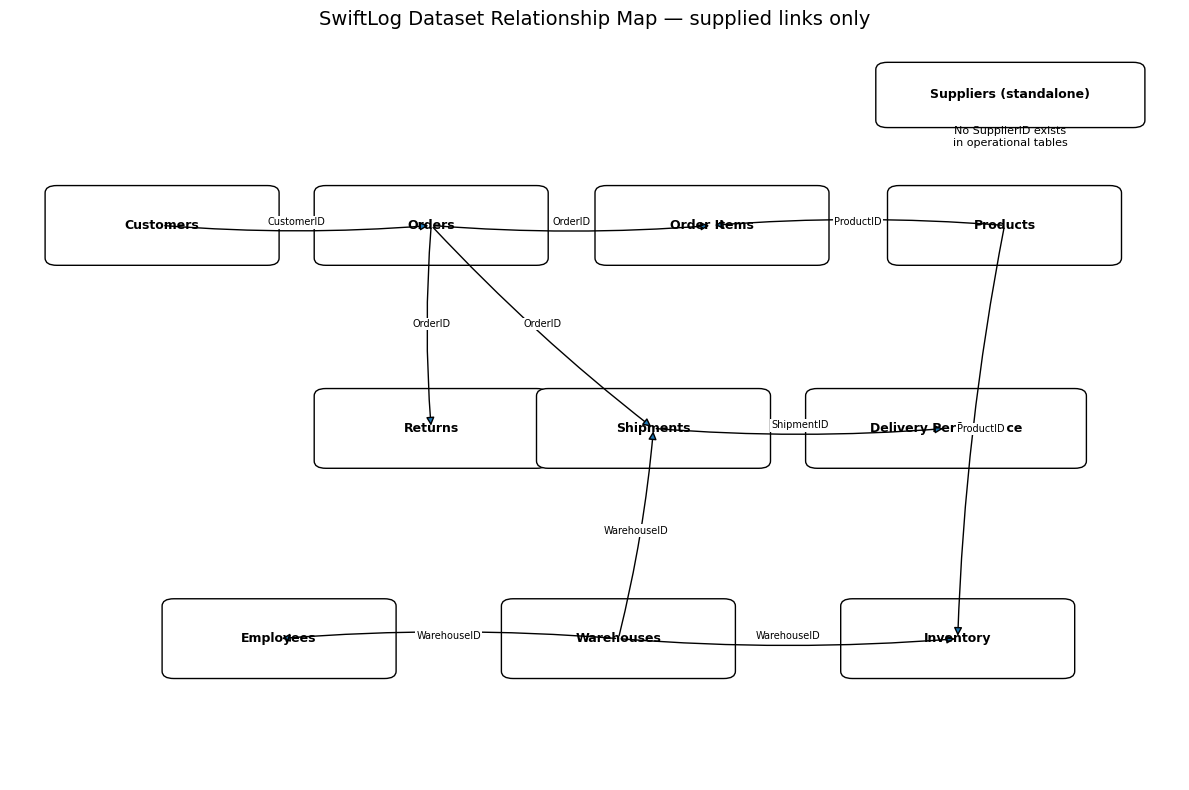

In [4]:

# Relationship diagram based only on relationships present in the supplied data.
fig, ax = plt.subplots(figsize=(12,8)); ax.axis('off')
pos = {
    'Customers':(0.04,0.72),'Orders':(0.27,0.72),'Order Items':(0.51,0.72),'Products':(0.76,0.72),
    'Returns':(0.27,0.44),'Shipments':(0.46,0.44),'Delivery Performance':(0.69,0.44),
    'Employees':(0.14,0.15),'Warehouses':(0.43,0.15),'Inventory':(0.72,0.15),
    'Suppliers (standalone)':(0.75,0.91)
}
size={k:(0.18,0.09) for k in pos}; size['Delivery Performance']=(0.22,0.09); size['Suppliers (standalone)']=(0.21,0.07)
for name,(x,y) in pos.items():
    w,h=size[name]; ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.01',fc='white',ec='black'))
    ax.text(x+w/2,y+h/2,name,ha='center',va='center',fontsize=9,weight='bold')
edges=[('Customers','Orders','CustomerID'),('Orders','Order Items','OrderID'),('Products','Order Items','ProductID'),('Orders','Returns','OrderID'),('Orders','Shipments','OrderID'),('Warehouses','Shipments','WarehouseID'),('Shipments','Delivery Performance','ShipmentID'),('Products','Inventory','ProductID'),('Warehouses','Inventory','WarehouseID'),('Warehouses','Employees','WarehouseID')]
for a,b,label in edges:
    xa,ya=pos[a]; wa,ha=size[a]; xb,yb=pos[b]; wb,hb=size[b]
    start=(xa+wa/2,ya+ha/2); end=(xb+wb/2,yb+hb/2)
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=12,connectionstyle='arc3,rad=0.04'))
    ax.text((start[0]+end[0])/2,(start[1]+end[1])/2,label,fontsize=7,ha='center',bbox=dict(fc='white',ec='none',pad=1))
ax.text(0.855,0.875,'No SupplierID exists\nin operational tables',ha='center',fontsize=8)
ax.set_xlim(0,1); ax.set_ylim(0,1.03); ax.set_title('SwiftLog Dataset Relationship Map — supplied links only',fontsize=14)
plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'Visualizations/Charts/fig01_dataset_relationship_map.png',dpi=180,bbox_inches='tight'); plt.show()



## Part 2 — Data Cleaning & Preprocessing
The cleaning strategy is conservative: standardise data types and text, validate ranges, preserve stock-movement rows, and document structural gaps instead of manufacturing data. The 236 orders without order-item records are retained in the order-level analytical dataset and marked explicitly with `OrderItemDataAvailable = 0`.


In [5]:

# Parse orders and add reusable calendar fields.
orders=tables['Orders'].copy(); orders['OrderDate']=pd.to_datetime(orders['OrderDate'],errors='raise')
orders['OrderYear']=orders.OrderDate.dt.year; orders['OrderMonth']=orders.OrderDate.dt.month
orders['OrderMonthName']=orders.OrderDate.dt.month_name(); orders['OrderQuarter']=orders.OrderDate.dt.quarter
orders['OrderDayOfWeek']=orders.OrderDate.dt.day_name(); tables['Orders']=orders

# Basic range checks — diagnose rather than delete outliers automatically.
assert (tables['Order_Items'].Quantity>0).all()
assert (tables['Products'].UnitPrice>0).all()
assert (tables['Inventory'].Stock>=0).all()
assert (tables['Shipments'].DelayDays>=0).all()
assert (tables['Delivery_Performance'].DelayDays>=0).all()

# Inventory: preserve all movement rows; build separate aggregated reporting view.
inventory_aggregated=(tables['Inventory'].groupby(['WarehouseID','ProductID'],as_index=False)
                      .agg(TotalStock=('Stock','sum'),StockMovementRecords=('Stock','size'),AverageStockPerRecord=('Stock','mean')))

# Observed delivery rule — inferred, not supplied in the dictionary.
display(pd.crosstab(tables['Delivery_Performance'].Status,tables['Delivery_Performance'].DelayDays))

for name,df in tables.items():
    if name!='Data_Dictionary':
        df.to_csv(OUTPUT_ROOT/f'Data/Cleaned_Datasets/SwiftLog_{name}_Cleaned.csv',index=False)
inventory_aggregated.to_csv(OUTPUT_ROOT/'Data/Cleaned_Datasets/SwiftLog_Inventory_Aggregated.csv',index=False)
print('Cleaned datasets exported.')


DelayDays,0,1,2,3,4,5,6,7
Status,,,,,,,,
Delayed,0,0,0,605,616,668,664,633
On Time,611,592,611,0,0,0,0,0


Cleaned datasets exported.



### Assumptions and Data Limitations
1. **Suppliers:** standalone reference table; no fabricated supplier-performance linkage.
2. **Warehouse capacity:** absent. Inventory quantity, product breadth and shipment count are used only as operational-load proxies.
3. **Inventory:** repeated Warehouse–Product rows are stock movements and are retained. Aggregation is created separately for reporting.
4. **Delivery status:** the dataset shows `On Time` for 0–2 delay days and `Delayed` from 3–7 days. This is an inferred dataset pattern, not a supplied policy definition.
5. **Returns:** return records identify an `OrderID` but not a `ProductID` or order line. Product/category analysis therefore measures exposure to returned orders, not confirmed product return rate.
6. **Order-item coverage:** 236 of 5,000 orders have no order-item rows. They remain in delivery/customer analyses but have missing revenue/product features.
7. **Data dictionary:** only dataset-level descriptions are supplied; field meanings are inferred cautiously from names and structure.


## Part 3 — Integrated Analytical Dataset & Feature Engineering

In [6]:

# Revenue and product aggregation
lines=tables['Order_Items'].merge(tables['Products'],on='ProductID',validate='many_to_one')
lines['LineRevenue']=lines.Quantity*lines.UnitPrice
order_items=(lines.groupby('OrderID').agg(OrderRevenue=('LineRevenue','sum'),TotalUnits=('Quantity','sum'),DistinctProducts=('ProductID','nunique'),UniqueCategories=('Category','nunique')).reset_index())
catrev=lines.groupby(['OrderID','Category'],as_index=False).LineRevenue.sum()
dominant=catrev.sort_values(['OrderID','LineRevenue'],ascending=[True,False]).drop_duplicates('OrderID')[['OrderID','Category']].rename(columns={'Category':'DominantCategory'})
order_items=order_items.merge(dominant,on='OrderID')

# Delivery / warehouse integration
ship=tables['Shipments'].merge(tables['Delivery_Performance'],on='ShipmentID',suffixes=('_Shipment','_Performance'),validate='one_to_one')
assert (ship.DelayDays_Shipment==ship.DelayDays_Performance).all()
ship=ship.rename(columns={'DelayDays_Performance':'DelayDays','Status':'DeliveryStatus'}).drop(columns='DelayDays_Shipment')
ship['IsDelayed']=(ship.DeliveryStatus=='Delayed').astype(int)
ship=ship.merge(tables['Warehouses'],on='WarehouseID',validate='many_to_one').rename(columns={'Location':'WarehouseLocation'})

# Return is an order-level outcome.
ret=tables['Returns'].groupby('OrderID').agg(ReturnCount=('ReturnID','count')).reset_index(); ret['HasReturn']=1

# Preserve all 5,000 orders using left merge for item-derived features.
base=(tables['Orders'].merge(tables['Customers'],on='CustomerID',validate='many_to_one')
      .merge(order_items,on='OrderID',how='left',validate='one_to_one')
      .merge(ship[['ShipmentID','OrderID','WarehouseID','DelayDays','DeliveryStatus','IsDelayed','WarehouseLocation']],on='OrderID',validate='one_to_one')
      .merge(ret,on='OrderID',how='left'))
base['OrderItemDataAvailable']=base.OrderRevenue.notna().astype(int)
base['ReturnCount']=base.ReturnCount.fillna(0).astype(int); base['HasReturn']=base.HasReturn.fillna(0).astype(int)

# Strictly prior customer features — useful for future predictive models.
base=base.sort_values(['CustomerID','OrderDate','OrderID']).reset_index(drop=True)
base['PriorCustomerOrders']=base.groupby('CustomerID').cumcount()
base['PriorCustomerSpend']=base.groupby('CustomerID').OrderRevenue.transform(lambda s:s.fillna(0).cumsum())-base.OrderRevenue.fillna(0)
base['PriorCustomerAvgSpend']=np.where(base.PriorCustomerOrders>0,base.PriorCustomerSpend/base.PriorCustomerOrders,0)

# Demand/seasonal descriptive features.
month_volume=base.groupby('OrderMonth').size().rename('MonthlyOrderVolume')
month_revenue=base.groupby('OrderMonth').OrderRevenue.sum(min_count=1).rename('MonthlyRevenue')
base=base.merge(month_volume,on='OrderMonth').merge(month_revenue,on='OrderMonth')
base['SeasonalDemandIndicator']=np.where(base.MonthlyOrderVolume>month_volume.median(),'High Demand','Normal/Low Demand')

# Warehouse load proxies. These are NOT true utilisation rates because capacity is absent.
wh_stock=inventory_aggregated.groupby('WarehouseID').agg(WarehouseStockProxy=('TotalStock','sum'),WarehouseProductBreadth=('ProductID','nunique')).reset_index()
wh_ship=ship.groupby('WarehouseID').agg(WarehouseShipmentCount=('ShipmentID','count'),WarehouseAvgDelay=('DelayDays','mean'),WarehouseDelayedRate=('IsDelayed','mean')).reset_index()
wh_emp=tables['Employees'].groupby('WarehouseID').size().rename('WarehouseEmployeeCount').reset_index()
warehouse_metrics=(tables['Warehouses'].merge(wh_stock,on='WarehouseID',how='left').merge(wh_ship,on='WarehouseID',how='left').merge(wh_emp,on='WarehouseID',how='left'))
warehouse_metrics['WarehouseOperationalLoadProxy']=0.5*(warehouse_metrics.WarehouseStockProxy/warehouse_metrics.WarehouseStockProxy.max())+0.5*(warehouse_metrics.WarehouseShipmentCount/warehouse_metrics.WarehouseShipmentCount.max())
base=base.merge(warehouse_metrics[['WarehouseID','WarehouseStockProxy','WarehouseProductBreadth','WarehouseShipmentCount','WarehouseEmployeeCount','WarehouseOperationalLoadProxy']],on='WarehouseID',how='left')

# Inventory turnover proxy: shipped units divided by aggregated stock movement quantity.
units_wp=(lines.merge(tables['Shipments'][['OrderID','WarehouseID']],on='OrderID',validate='many_to_one')
          .groupby(['WarehouseID','ProductID'],as_index=False).Quantity.sum().rename(columns={'Quantity':'UnitsShipped'}))
inv_proxy=inventory_aggregated.merge(units_wp,on=['WarehouseID','ProductID'],how='left')
inv_proxy.UnitsShipped=inv_proxy.UnitsShipped.fillna(0)
inv_proxy['InventoryTurnoverProxy']=np.where(inv_proxy.TotalStock>0,inv_proxy.UnitsShipped/inv_proxy.TotalStock,np.nan)

# Descriptive delivery efficiency only; not a predictor because it is derived from the outcome.
base['DeliveryEfficiencyScore']=100*(1-base.DelayDays/base.DelayDays.max())

feature_cols=['OrderID','OrderItemDataAvailable','CustomerID','OrderDate','OrderYear','OrderMonth','OrderMonthName','OrderQuarter','OrderDayOfWeek','Status','CustomerName','City','OrderRevenue','TotalUnits','DistinctProducts','UniqueCategories','DominantCategory','PriorCustomerOrders','PriorCustomerSpend','PriorCustomerAvgSpend','MonthlyOrderVolume','MonthlyRevenue','SeasonalDemandIndicator','ShipmentID','WarehouseID','WarehouseLocation','WarehouseStockProxy','WarehouseProductBreadth','WarehouseShipmentCount','WarehouseEmployeeCount','WarehouseOperationalLoadProxy','DelayDays','DeliveryStatus','IsDelayed','DeliveryEfficiencyScore','HasReturn','ReturnCount']
feature=base[feature_cols].sort_values('OrderID').reset_index(drop=True)
feature.to_csv(OUTPUT_ROOT/'Data/Feature_Engineered_Dataset.csv',index=False)
print('Feature dataset shape:', feature.shape)
print('Orders with product/revenue coverage:', int(feature.OrderItemDataAvailable.sum()), '/', len(feature))
display(feature.head())


Feature dataset shape: (5000, 37)
Orders with product/revenue coverage: 4764 / 5000


,OrderID,OrderItemDataAvailable,CustomerID,OrderDate,OrderYear,OrderMonth,OrderMonthName,OrderQuarter,OrderDayOfWeek,Status,...,WarehouseProductBreadth,WarehouseShipmentCount,WarehouseEmployeeCount,WarehouseOperationalLoadProxy,DelayDays,DeliveryStatus,IsDelayed,DeliveryEfficiencyScore,HasReturn,ReturnCount
0,O00001,1,C0807,2026-07-22,2026,7,July,3,Wednesday,Delivered,...,157,334,15,0.883388,0,On Time,0,100.000000,0,0
1,O00002,1,C0426,2026-04-11,2026,4,April,2,Saturday,Cancelled,...,170,344,17,0.892931,2,On Time,0,71.428571,0,0
2,O00003,1,C0810,2026-01-07,2026,1,January,1,Wednesday,Cancelled,...,170,371,17,0.940794,0,On Time,0,100.000000,0,0
3,O00004,1,C0596,2026-01-30,2026,1,January,1,Friday,Pending,...,163,334,14,0.857304,0,On Time,0,100.000000,0,0
4,O00005,1,C0588,2026-05-16,2026,5,May,2,Saturday,Pending,...,164,319,14,0.876124,3,Delayed,1,57.142857,0,0



## Part 4 — Exploratory Data Analysis
The assignment requires at least 15 professional visualisations. The following figures cover univariate, bivariate and multivariate operational questions. Every interpretation is based on code executed here; no figures are manually invented.


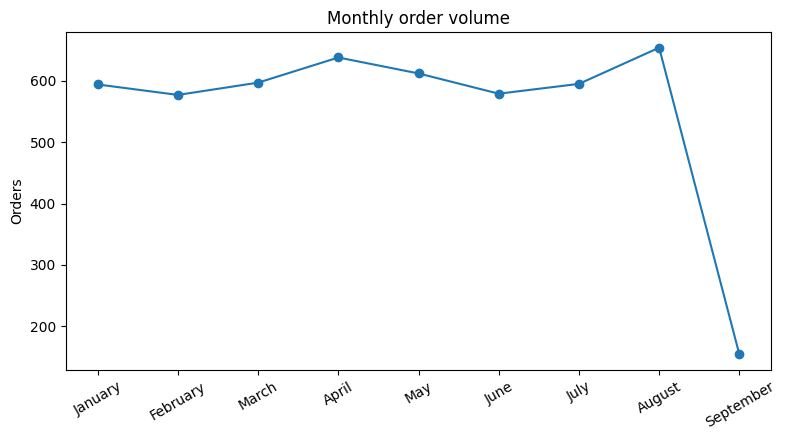

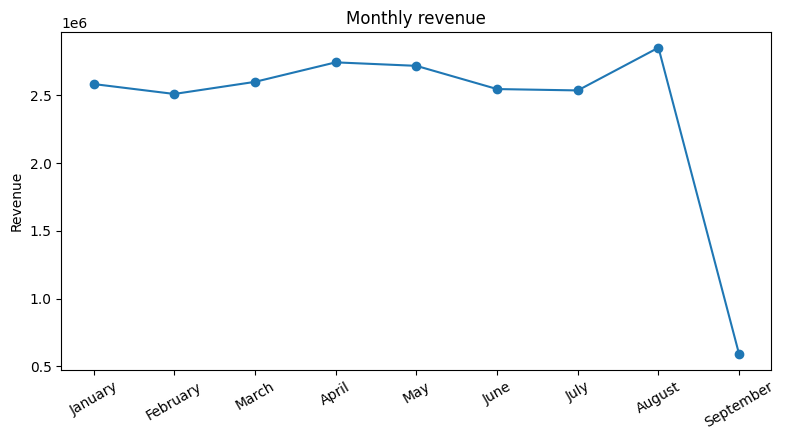

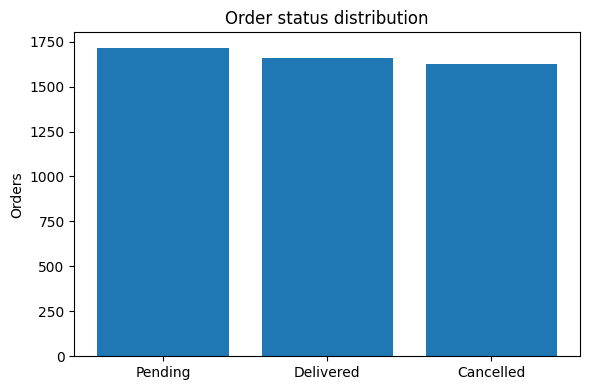

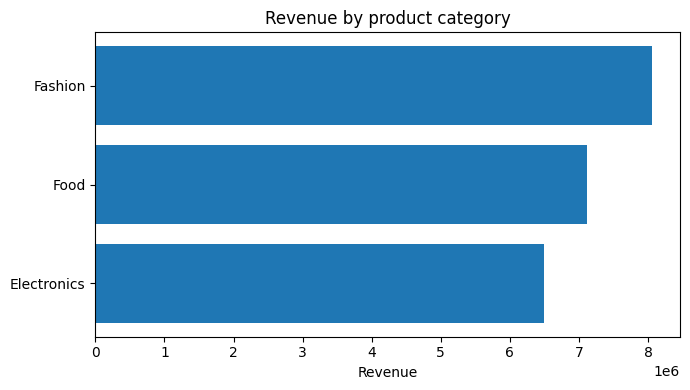

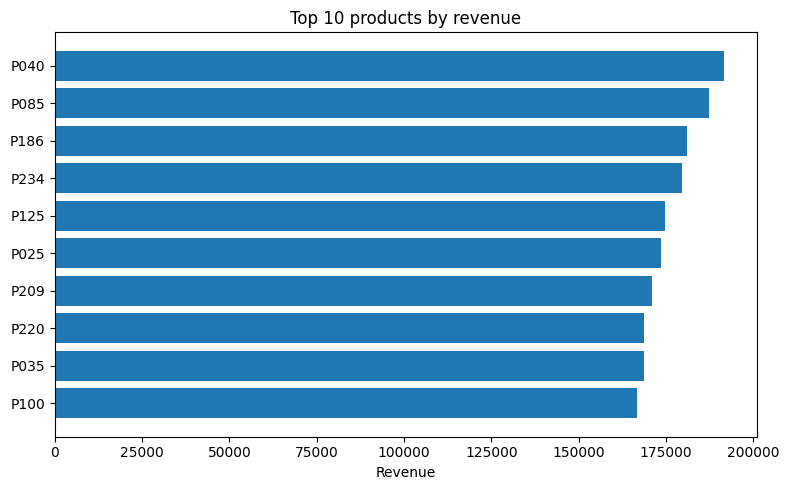

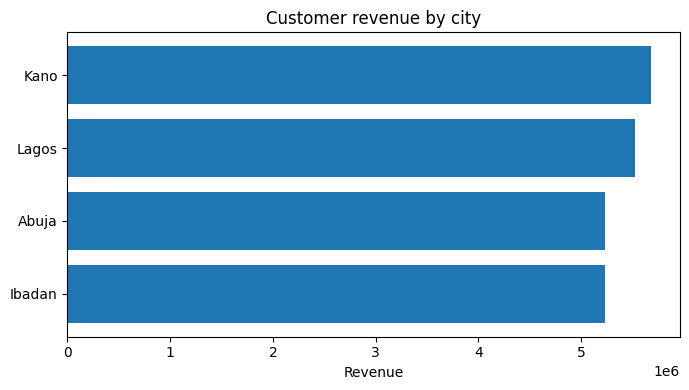

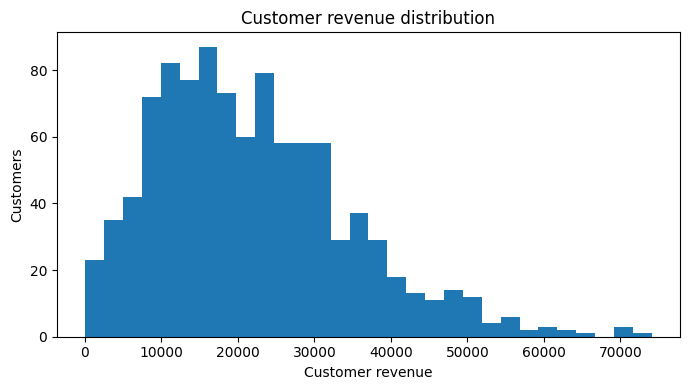

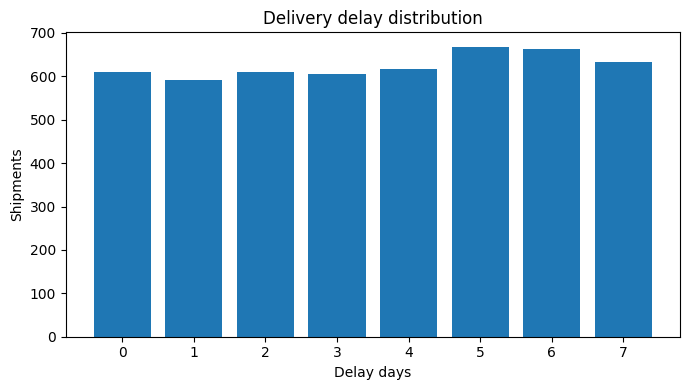

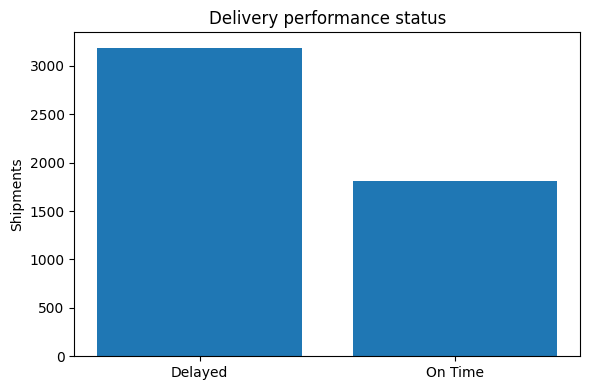

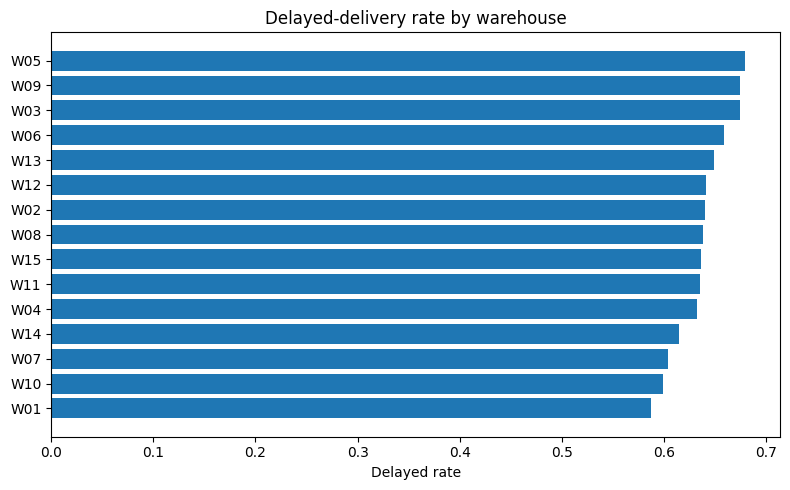

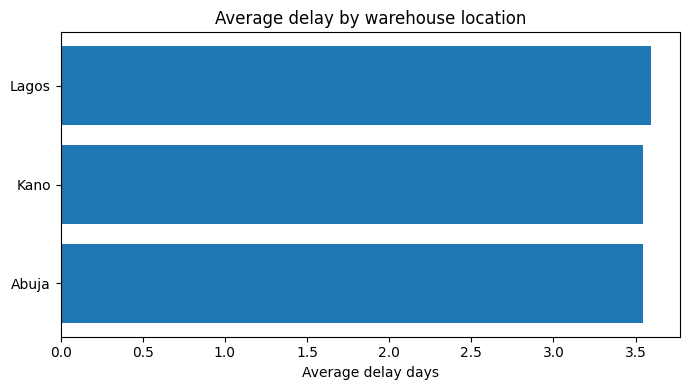

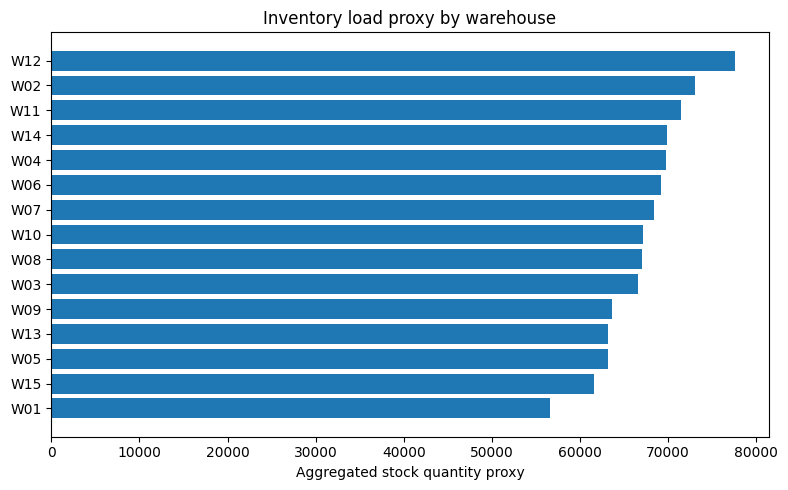

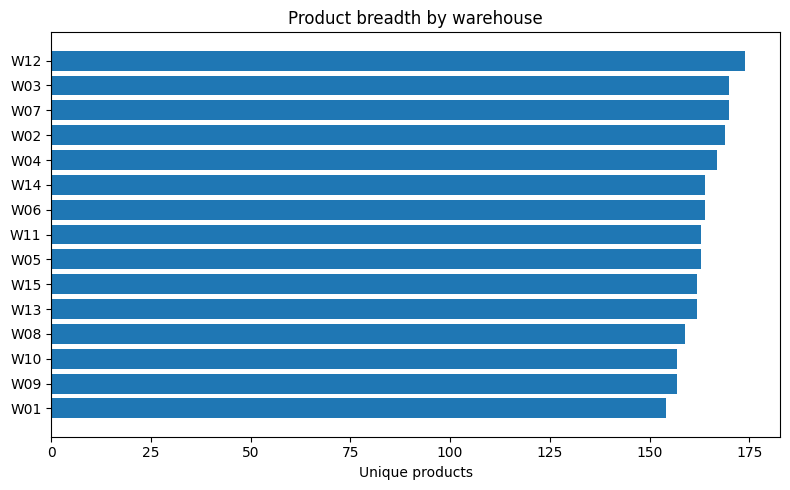

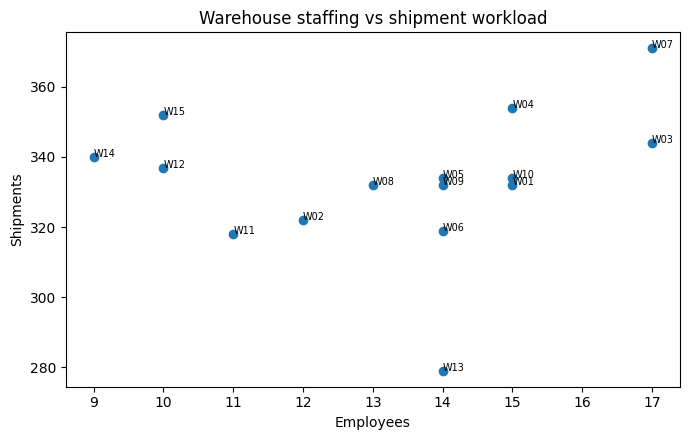

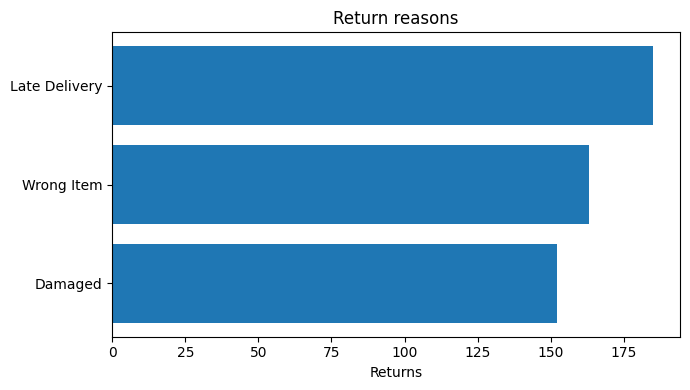

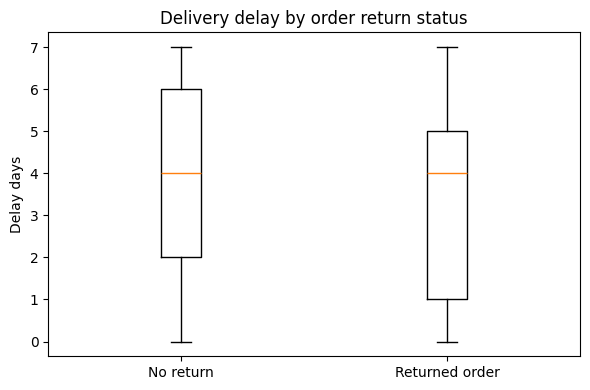

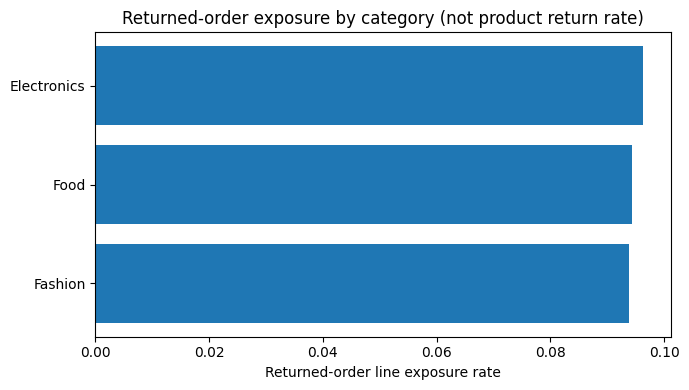

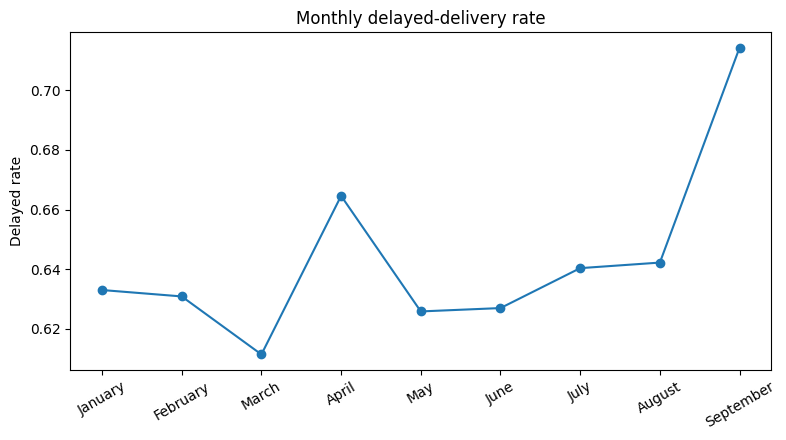

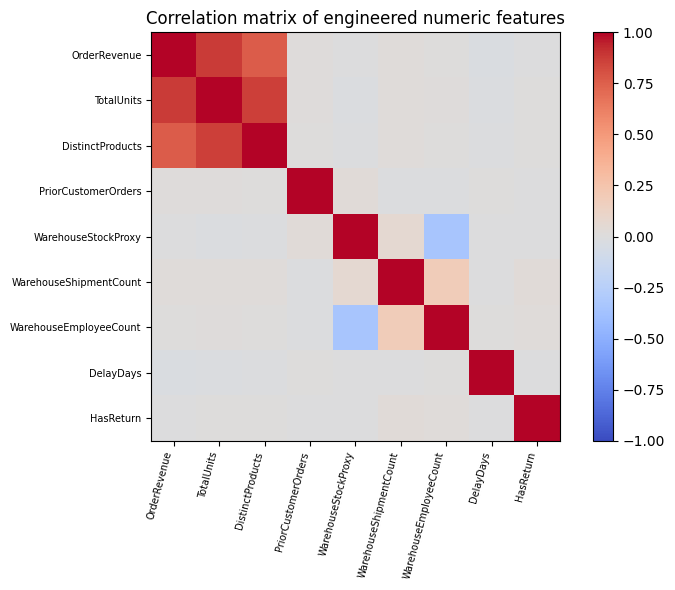

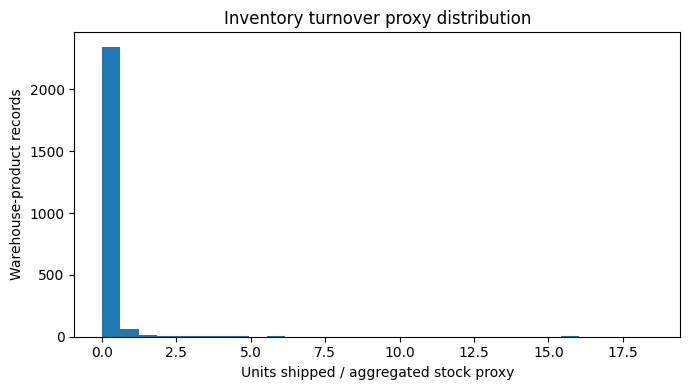

EDA headline findings
Total revenue from 4,764 orders with item data: 21668065.85
Top category: Fashion 8059602.65
Top product: P040
Overall delayed rate: 0.6372
Overall average delay: 3.5696
Return-order rate: 0.0946
Peak order month: August


In [7]:

C=OUTPUT_ROOT/'Visualizations/Charts'
def finish(name,title=None):
    if title: plt.title(title)
    plt.tight_layout(); plt.savefig(C/name,dpi=180,bbox_inches='tight'); plt.show()

# Core summary tables
monthly=feature.groupby('OrderMonth').agg(Orders=('OrderID','count'),Revenue=('OrderRevenue','sum'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean')).reset_index(); monthly['MonthName']=pd.to_datetime(monthly.OrderMonth,format='%m').dt.month_name()
category=lines.groupby('Category').agg(Revenue=('LineRevenue','sum'),Units=('Quantity','sum'),Orders=('OrderID','nunique')).reset_index().sort_values('Revenue',ascending=False)
product=lines.groupby(['ProductID','Category','UnitPrice']).agg(ProductRevenue=('LineRevenue','sum'),UnitsSold=('Quantity','sum'),Orders=('OrderID','nunique')).reset_index()
city=feature.groupby('City').agg(Customers=('CustomerID','nunique'),Orders=('OrderID','count'),Revenue=('OrderRevenue','sum'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean')).reset_index()
whperf=feature.groupby(['WarehouseID','WarehouseLocation']).agg(Shipments=('ShipmentID','count'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean'),RevenueHandled=('OrderRevenue','sum')).reset_index().merge(warehouse_metrics[['WarehouseID','WarehouseStockProxy','WarehouseProductBreadth','WarehouseEmployeeCount','WarehouseOperationalLoadProxy']],on='WarehouseID')
return_reasons=tables['Returns'].Reason.value_counts().rename_axis('Reason').reset_index(name='Returns')
ret_exp=lines.merge(feature[['OrderID','HasReturn']],on='OrderID').groupby('Category').agg(OrderLines=('OrderItemID','count'),ReturnedOrderLines=('HasReturn','sum')).reset_index(); ret_exp['ReturnedOrderLineExposureRate']=ret_exp.ReturnedOrderLines/ret_exp.OrderLines

# 2 monthly orders
plt.figure(figsize=(8,4.5)); plt.plot(monthly.MonthName,monthly.Orders,marker='o'); plt.xticks(rotation=30); plt.ylabel('Orders'); finish('fig03_monthly_orders.png','Monthly order volume')
# 3 revenue trend
plt.figure(figsize=(8,4.5)); plt.plot(monthly.MonthName,monthly.Revenue,marker='o'); plt.xticks(rotation=30); plt.ylabel('Revenue'); finish('fig04_monthly_revenue.png','Monthly revenue')
# 4 order status
v=tables['Orders'].Status.value_counts(); plt.figure(figsize=(6,4)); plt.bar(v.index,v.values); plt.ylabel('Orders'); finish('fig05_order_status.png','Order status distribution')
# 5 category revenue
cc=category.sort_values('Revenue'); plt.figure(figsize=(7,4)); plt.barh(cc.Category,cc.Revenue); plt.xlabel('Revenue'); finish('fig06_category_revenue.png','Revenue by product category')
# 6 top products
p10=product.nlargest(10,'ProductRevenue').sort_values('ProductRevenue'); plt.figure(figsize=(8,5)); plt.barh(p10.ProductID,p10.ProductRevenue); plt.xlabel('Revenue'); finish('fig07_top_products_revenue.png','Top 10 products by revenue')
# 7 customer city revenue
ct=city.sort_values('Revenue'); plt.figure(figsize=(7,4)); plt.barh(ct.City,ct.Revenue); plt.xlabel('Revenue'); finish('fig08_city_revenue.png','Customer revenue by city')
# 8 customer revenue distribution
cust_tmp=feature.groupby('CustomerID').OrderRevenue.sum(min_count=1).dropna(); plt.figure(figsize=(7,4)); plt.hist(cust_tmp,bins=30); plt.xlabel('Customer revenue'); plt.ylabel('Customers'); finish('fig09_customer_revenue_distribution.png','Customer revenue distribution')
# 9 delay days
v=feature.DelayDays.value_counts().sort_index(); plt.figure(figsize=(7,4)); plt.bar(v.index.astype(str),v.values); plt.xlabel('Delay days'); plt.ylabel('Shipments'); finish('fig10_delay_distribution.png','Delivery delay distribution')
# 10 delivery status
v=feature.DeliveryStatus.value_counts(); plt.figure(figsize=(6,4)); plt.bar(v.index,v.values); plt.ylabel('Shipments'); finish('fig11_delivery_status.png','Delivery performance status')
# 11 warehouse delay rate
w=whperf.sort_values('DelayedRate'); plt.figure(figsize=(8,5)); plt.barh(w.WarehouseID,w.DelayedRate); plt.xlabel('Delayed rate'); finish('fig12_warehouse_delay_rate.png','Delayed-delivery rate by warehouse')
# 12 warehouse location delay
loc=feature.groupby('WarehouseLocation').DelayDays.mean().sort_values(); plt.figure(figsize=(7,4)); plt.barh(loc.index,loc.values); plt.xlabel('Average delay days'); finish('fig13_location_avg_delay.png','Average delay by warehouse location')
# 13 inventory load proxy
w=warehouse_metrics.sort_values('WarehouseStockProxy'); plt.figure(figsize=(8,5)); plt.barh(w.WarehouseID,w.WarehouseStockProxy); plt.xlabel('Aggregated stock quantity proxy'); finish('fig14_warehouse_inventory_load_proxy.png','Inventory load proxy by warehouse')
# 14 product breadth
w=warehouse_metrics.sort_values('WarehouseProductBreadth'); plt.figure(figsize=(8,5)); plt.barh(w.WarehouseID,w.WarehouseProductBreadth); plt.xlabel('Unique products'); finish('fig15_warehouse_product_breadth.png','Product breadth by warehouse')
# 15 staffing vs shipment workload
plt.figure(figsize=(7,4.5)); plt.scatter(warehouse_metrics.WarehouseEmployeeCount,warehouse_metrics.WarehouseShipmentCount)
for _,r in warehouse_metrics.iterrows(): plt.annotate(r.WarehouseID,(r.WarehouseEmployeeCount,r.WarehouseShipmentCount),fontsize=7)
plt.xlabel('Employees'); plt.ylabel('Shipments'); finish('fig16_staffing_vs_shipments.png','Warehouse staffing vs shipment workload')
# 16 return reasons
rr=return_reasons.sort_values('Returns'); plt.figure(figsize=(7,4)); plt.barh(rr.Reason,rr.Returns); plt.xlabel('Returns'); finish('fig17_return_reasons.png','Return reasons')
# 17 delay vs returns
plt.figure(figsize=(6,4)); plt.boxplot([feature.loc[feature.HasReturn==0,'DelayDays'],feature.loc[feature.HasReturn==1,'DelayDays']],labels=['No return','Returned order']); plt.ylabel('Delay days'); finish('fig18_delay_vs_returns.png','Delivery delay by order return status')
# 18 returned-order exposure by category
re=ret_exp.sort_values('ReturnedOrderLineExposureRate'); plt.figure(figsize=(7,4)); plt.barh(re.Category,re.ReturnedOrderLineExposureRate); plt.xlabel('Returned-order line exposure rate'); finish('fig19_category_return_exposure.png','Returned-order exposure by category (not product return rate)')
# 19 monthly delayed rate
plt.figure(figsize=(8,4.5)); plt.plot(monthly.MonthName,monthly.DelayedRate,marker='o'); plt.xticks(rotation=30); plt.ylabel('Delayed rate'); finish('fig23_monthly_delayed_rate.png','Monthly delayed-delivery rate')
# 20 correlation matrix
cols=['OrderRevenue','TotalUnits','DistinctProducts','PriorCustomerOrders','WarehouseStockProxy','WarehouseShipmentCount','WarehouseEmployeeCount','DelayDays','HasReturn']
corr=feature[cols].corr(); plt.figure(figsize=(8,6)); im=plt.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1); plt.colorbar(im); plt.xticks(range(len(cols)),cols,rotation=75,ha='right',fontsize=7); plt.yticks(range(len(cols)),cols,fontsize=7); finish('fig24_correlation_matrix.png','Correlation matrix of engineered numeric features')
# 21 turnover proxy
vals=inv_proxy.InventoryTurnoverProxy.replace([np.inf,-np.inf],np.nan).dropna(); plt.figure(figsize=(7,4)); plt.hist(vals,bins=30); plt.xlabel('Units shipped / aggregated stock proxy'); plt.ylabel('Warehouse-product records'); finish('fig25_inventory_turnover_proxy.png','Inventory turnover proxy distribution')

print('EDA headline findings')
print('Total revenue from 4,764 orders with item data:', round(feature.OrderRevenue.sum(),2))
print('Top category:', category.iloc[0].Category, round(category.iloc[0].Revenue,2))
print('Top product:', product.sort_values('ProductRevenue',ascending=False).iloc[0].ProductID)
print('Overall delayed rate:', round(feature.IsDelayed.mean(),4))
print('Overall average delay:', round(feature.DelayDays.mean(),4))
print('Return-order rate:', round(feature.HasReturn.mean(),4))
print('Peak order month:', monthly.sort_values('Orders',ascending=False).iloc[0].MonthName)



## Part 5 — Descriptive & Inferential Statistical Analysis
Because delay days and order revenue are discrete/skewed rather than safely assumed normal, the primary inferential tests use non-parametric methods. Statistical significance is interpreted together with effect size and business meaning.


In [8]:

# Descriptive statistics including variance, skewness and kurtosis.
stat_cols=['OrderRevenue','TotalUnits','DistinctProducts','DelayDays','PriorCustomerOrders','WarehouseStockProxy','WarehouseShipmentCount','WarehouseEmployeeCount']
stats_table=[]
for c in stat_cols:
    s=feature[c].dropna()
    stats_table.append([c,s.mean(),s.median(),s.mode().iloc[0] if len(s.mode()) else np.nan,s.var(),s.std(),s.skew(),s.kurt(),s.min(),s.max()])
descriptive=pd.DataFrame(stats_table,columns=['Variable','Mean','Median','Mode','Variance','StdDev','Skewness','Kurtosis','Min','Max'])
display(descriptive)
descriptive.to_csv(OUTPUT_ROOT/'Analysis/descriptive_statistics.csv',index=False)

# H1: delivery delays across warehouses
warehouse_groups=[g.DelayDays.values for _,g in feature.groupby('WarehouseID')]
h1=stats.kruskal(*warehouse_groups); eps1=max(0,(h1.statistic-feature.WarehouseID.nunique()+1)/(len(feature)-feature.WarehouseID.nunique()))
# H2: delivery delay for returned vs non-returned orders
ret_delay=feature.loc[feature.HasReturn==1,'DelayDays']; nonret_delay=feature.loc[feature.HasReturn==0,'DelayDays']
h2=stats.mannwhitneyu(ret_delay,nonret_delay,alternative='two-sided'); rb=abs(1-2*h2.statistic/(len(ret_delay)*len(nonret_delay)))
# H3: order revenue across customer cities, complete revenue records only
citygroups=[g.OrderRevenue.dropna().values for _,g in feature.groupby('City')]; h3=stats.kruskal(*citygroups); n3=feature.OrderRevenue.notna().sum(); eps3=max(0,(h3.statistic-feature.City.nunique()+1)/(n3-feature.City.nunique()))

hypothesis_results=pd.DataFrame([
    ['H1','Equal delivery-delay distributions across warehouses','Kruskal-Wallis',h1.statistic,h1.pvalue,eps1,'Fail to reject' if h1.pvalue>=.05 else 'Reject'],
    ['H2','Equal delivery-delay distributions for returned and non-returned orders','Mann-Whitney U',h2.statistic,h2.pvalue,rb,'Fail to reject' if h2.pvalue>=.05 else 'Reject'],
    ['H3','Equal order-revenue distributions across customer cities','Kruskal-Wallis',h3.statistic,h3.pvalue,eps3,'Fail to reject' if h3.pvalue>=.05 else 'Reject'],
],columns=['ID','Null Hypothesis','Test','Statistic','p-value','Effect Size','Decision'])
display(hypothesis_results)
hypothesis_results.to_csv(OUTPUT_ROOT/'Analysis/hypothesis_tests.csv',index=False)


,Variable,Mean,Median,Mode,Variance,StdDev,Skewness,Kurtosis,Min,Max
0,OrderRevenue,4548.292580,3949.47,366.5,9.915637e+06,3148.910515,0.992871,0.981549,11.78,19290.34
1,TotalUnits,17.305206,16.00,10.0,1.077145e+02,10.378560,0.871844,0.802546,1.00,71.00
2,DistinctProducts,3.128463,3.00,2.0,2.633084e+00,1.622678,0.765338,0.425329,1.00,11.00
3,DelayDays,3.569600,4.00,5.0,5.250606e+00,2.291420,-0.053563,-1.240650,0.00,7.00
4,PriorCustomerOrders,2.550200,2.00,0.0,4.832847e+00,2.198374,0.911633,0.631081,0.00,14.00
5,WarehouseStockProxy,67206.563400,67169.00,68338.0,2.447570e+07,4947.292196,-0.086444,0.073570,56539.00,77517.00
6,WarehouseShipmentCount,334.512000,334.00,332.0,3.719582e+02,19.286219,-0.784316,1.984000,279.00,371.00
7,WarehouseEmployeeCount,13.355800,14.00,14.0,5.878382e+00,2.424537,-0.275725,-0.947555,9.00,17.00


,ID,Null Hypothesis,Test,Statistic,p-value,Effect Size,Decision
0,H1,Equal delivery-delay distributions across ware...,Kruskal-Wallis,1.003863e+01,0.759354,0.000000,Fail to reject
1,H2,Equal delivery-delay distributions for returne...,Mann-Whitney U,1.069995e+06,0.982771,0.000598,Fail to reject
2,H3,Equal order-revenue distributions across custo...,Kruskal-Wallis,3.431916e+00,0.329700,0.000091,Fail to reject



### Statistical interpretation
- **H1:** no statistically credible evidence that delay distributions differ by warehouse in this synthetic sample. Observed warehouse rate differences should therefore be treated as operational monitoring signals, not proof of warehouse-caused delay.
- **H2:** return occurrence is not associated with a meaningful difference in delivery delay. Even though `Late Delivery` is a common stated return reason, overall return occurrence is not explained by delay alone.
- **H3:** there is no meaningful evidence that order-revenue distributions differ by customer city. Geographic revenue totals mainly reflect customer/order volume rather than a strong per-order city effect.

Rejected or unsupported hypotheses are retained as useful results rather than removed from the project narrative.


## Part 6 — Segmentation & Pattern Discovery

In [9]:

# Customer value/frequency segmentation — 3 clusters chosen for clearer separation.
customer=(feature.groupby(['CustomerID','CustomerName','City']).agg(
    CustomerRevenue=('OrderRevenue',lambda x:x.sum(min_count=1)),Orders=('OrderID','nunique'),RevenueObservedOrders=('OrderItemDataAvailable','sum'),
    AvgOrderValue=('OrderRevenue','mean'),TotalUnits=('TotalUnits',lambda x:x.sum(min_count=1)),ReturnOrders=('HasReturn','sum'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean')).reset_index())
customer['CustomerRevenue']=customer.CustomerRevenue.fillna(0); customer['AvgOrderValue']=customer.AvgOrderValue.fillna(0); customer['TotalUnits']=customer.TotalUnits.fillna(0); customer['ReturnOrderRate']=customer.ReturnOrders/customer.Orders
X=customer[['CustomerRevenue','Orders','AvgOrderValue']]; Xs=StandardScaler().fit_transform(X)
km=KMeans(n_clusters=3,random_state=SEED,n_init=20); customer['CustomerCluster']=km.fit_predict(Xs); customer_sil=silhouette_score(Xs,customer.CustomerCluster)
prof=customer.groupby('CustomerCluster')[['CustomerRevenue','Orders','AvgOrderValue']].mean(); labels={}
for i,r in prof.iterrows():
    if r.Orders==prof.Orders.max(): labels[i]='High-Value Loyal'
    elif r.AvgOrderValue==prof.AvgOrderValue.max(): labels[i]='High-Value Occasional'
    else: labels[i]='Core / Lower-Value'
customer['CustomerSegment']=customer.CustomerCluster.map(labels)
customer.to_csv(OUTPUT_ROOT/'Analysis/customer_segments.csv',index=False)

# Warehouse exploratory segmentation — small n=15, so interpret cautiously.
WX=warehouse_metrics[['WarehouseStockProxy','WarehouseShipmentCount','WarehouseAvgDelay','WarehouseDelayedRate','WarehouseEmployeeCount']]
WXs=StandardScaler().fit_transform(WX); wk=KMeans(n_clusters=3,random_state=SEED,n_init=20); warehouse_metrics['WarehouseCluster']=wk.fit_predict(WXs); warehouse_sil=silhouette_score(WXs,warehouse_metrics.WarehouseCluster)
warehouse_metrics.to_csv(OUTPUT_ROOT/'Analysis/warehouse_segments.csv',index=False)

# Product segmentation
product=lines.groupby(['ProductID','Category','UnitPrice']).agg(ProductRevenue=('LineRevenue','sum'),UnitsSold=('Quantity','sum'),Orders=('OrderID','nunique')).reset_index()
PX=product[['ProductRevenue','UnitsSold','Orders']]; PXs=StandardScaler().fit_transform(PX); pk=KMeans(n_clusters=4,random_state=SEED,n_init=20); product['ProductCluster']=pk.fit_predict(PXs); product_sil=silhouette_score(PXs,product.ProductCluster)
pp=product.groupby('ProductCluster')[['ProductRevenue','UnitsSold','Orders']].mean(); rev_rank=pp.ProductRevenue.rank(); unit_rank=pp.UnitsSold.rank(); pl={}
for i,r in pp.iterrows():
    if rev_rank[i]>=3 and unit_rank[i]>=3: pl[i]='Revenue & Volume Leaders'
    elif rev_rank[i]>=3: pl[i]='Premium Revenue'
    elif unit_rank[i]>=3: pl[i]='Volume Drivers'
    else: pl[i]='Long Tail'
product['ProductSegment']=product.ProductCluster.map(pl); product.to_csv(OUTPUT_ROOT/'Analysis/product_segments.csv',index=False)

print('Silhouette scores — exploratory, not proof of natural business classes:')
print('Customer:',round(customer_sil,3),'Warehouse:',round(warehouse_sil,3),'Product:',round(product_sil,3))
display(customer.groupby('CustomerSegment').agg(Customers=('CustomerID','count'),Revenue=('CustomerRevenue','sum'),AvgOrders=('Orders','mean'),AvgOrderValue=('AvgOrderValue','mean')).sort_values('Revenue',ascending=False))


Silhouette scores — exploratory, not proof of natural business classes:
Customer: 0.36 Warehouse: 0.301 Product: 0.33


,Customers,Revenue,AvgOrders,AvgOrderValue
CustomerSegment,,,,
High-Value Loyal,329,11480069.79,7.577508,4846.064595
High-Value Occasional,246,5398755.07,3.772358,6209.739638
Core / Lower-Value,416,4789240.99,3.795673,3182.875993


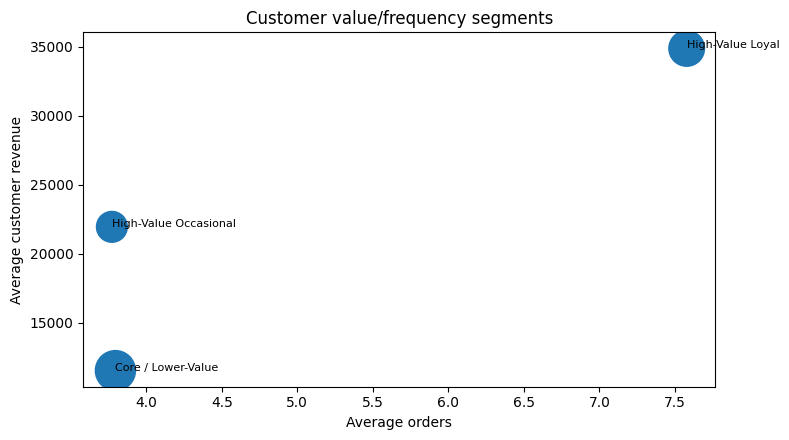

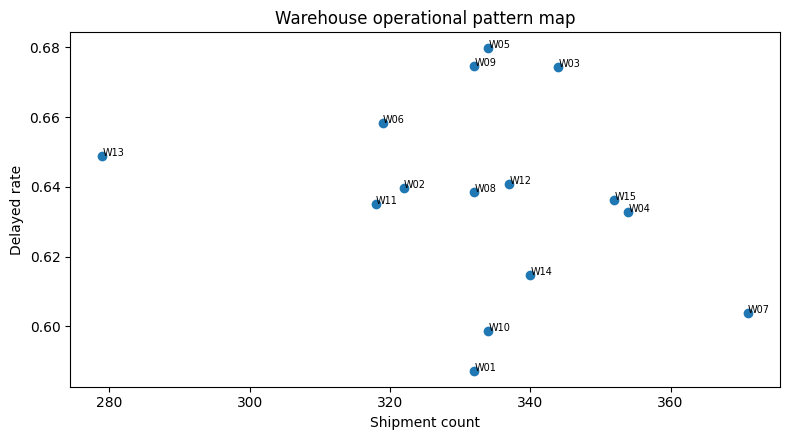

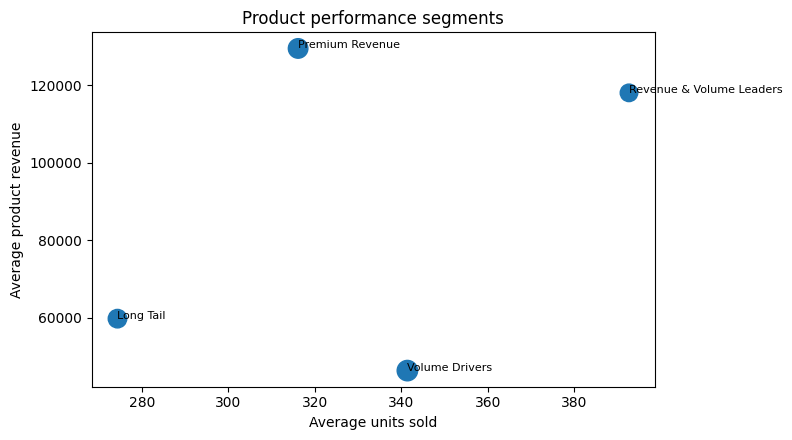

In [10]:

# Segmentation visuals
cs=customer.groupby('CustomerSegment').agg(Customers=('CustomerID','count'),AvgRevenue=('CustomerRevenue','mean'),AvgOrders=('Orders','mean')).reset_index()
plt.figure(figsize=(8,4.5)); plt.scatter(cs.AvgOrders,cs.AvgRevenue,s=cs.Customers*2)
for _,r in cs.iterrows(): plt.annotate(r.CustomerSegment,(r.AvgOrders,r.AvgRevenue),fontsize=8)
plt.xlabel('Average orders'); plt.ylabel('Average customer revenue'); plt.title('Customer value/frequency segments'); plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'Visualizations/Charts/fig20_customer_segments.png',dpi=180,bbox_inches='tight'); plt.show()

plt.figure(figsize=(8,4.5)); plt.scatter(warehouse_metrics.WarehouseShipmentCount,warehouse_metrics.WarehouseDelayedRate)
for _,r in warehouse_metrics.iterrows(): plt.annotate(r.WarehouseID,(r.WarehouseShipmentCount,r.WarehouseDelayedRate),fontsize=7)
plt.xlabel('Shipment count'); plt.ylabel('Delayed rate'); plt.title('Warehouse operational pattern map'); plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'Visualizations/Charts/fig21_warehouse_segments.png',dpi=180,bbox_inches='tight'); plt.show()

ps=product.groupby('ProductSegment').agg(Products=('ProductID','count'),AvgRevenue=('ProductRevenue','mean'),AvgUnits=('UnitsSold','mean')).reset_index()
plt.figure(figsize=(8,4.5)); plt.scatter(ps.AvgUnits,ps.AvgRevenue,s=ps.Products*3)
for _,r in ps.iterrows(): plt.annotate(r.ProductSegment,(r.AvgUnits,r.AvgRevenue),fontsize=8)
plt.xlabel('Average units sold'); plt.ylabel('Average product revenue'); plt.title('Product performance segments'); plt.tight_layout(); plt.savefig(OUTPUT_ROOT/'Visualizations/Charts/fig22_product_segments.png',dpi=180,bbox_inches='tight'); plt.show()


## Part 7 — Business Insights & Recommendations

In [11]:

# Evidence tables used to answer the assignment's ten business questions.
warehouse_perf=feature.groupby(['WarehouseID','WarehouseLocation']).agg(Shipments=('ShipmentID','count'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean'),RevenueHandled=('OrderRevenue','sum')).reset_index().sort_values('DelayedRate')
location_perf=feature.groupby('WarehouseLocation').agg(Shipments=('ShipmentID','count'),AvgDelay=('DelayDays','mean'),DelayedRate=('IsDelayed','mean')).reset_index().sort_values('AvgDelay',ascending=False)
category_perf=lines.groupby('Category').agg(Revenue=('LineRevenue','sum'),Units=('Quantity','sum'),Orders=('OrderID','nunique')).reset_index().sort_values('Revenue',ascending=False)
product_perf=lines.groupby('ProductID').agg(Revenue=('LineRevenue','sum'),Units=('Quantity','sum'),Orders=('OrderID','nunique')).reset_index().sort_values('Revenue',ascending=False)
returned_exposure=lines.merge(feature[['OrderID','HasReturn']],on='OrderID').groupby('Category').agg(OrderLines=('OrderItemID','count'),ReturnedOrderLines=('HasReturn','sum')).reset_index(); returned_exposure['ReturnedOrderExposure']=returned_exposure.ReturnedOrderLines/returned_exposure.OrderLines

print('1. Highest-value customer segment:')
display(customer.groupby('CustomerSegment').agg(Customers=('CustomerID','count'),Revenue=('CustomerRevenue','sum'),AvgRevenue=('CustomerRevenue','mean'),AvgOrders=('Orders','mean')).sort_values('Revenue',ascending=False))
print('2. Top products by revenue:'); display(product_perf.head(10))
print('3. Supplier underperformance: NOT determinable — no SupplierID link exists outside Suppliers.')
print('4. Warehouses requiring monitoring (highest delayed rates):'); display(warehouse_perf.sort_values('DelayedRate',ascending=False).head())
print('5. True product return rates: NOT determinable — Returns is order-level. Category exposure proxy:'); display(returned_exposure.sort_values('ReturnedOrderExposure',ascending=False))
print('6. Warehouse locations with greatest delays:'); display(location_perf)
print('7. Bottleneck: overall delayed rate =',round(feature.IsDelayed.mean(),4),'and 236 orders lack item-level product/revenue data.')
print('8. Predictive candidates: order size/value, product mix, season, customer prior history, warehouse/location and workload proxies. Outcome-derived fields must be excluded when predicting delay.')
print('9. Hidden patterns: warehouse and return delay hypotheses are unsupported; August has the highest order volume; Fashion leads revenue.')
print('10. Recommendations are documented in the technical report and README.')


1. Highest-value customer segment:


,Customers,Revenue,AvgRevenue,AvgOrders
CustomerSegment,,,,
High-Value Loyal,329,11480069.79,34893.829149,7.577508
High-Value Occasional,246,5398755.07,21946.158821,3.772358
Core / Lower-Value,416,4789240.99,11512.598534,3.795673


2. Top products by revenue:


,ProductID,Revenue,Units,Orders
39,P040,191463.68,404,73
84,P085,187416.00,380,62
185,P186,180896.24,392,75
233,P234,179609.25,425,70
124,P125,174691.66,442,74
24,P025,173580.88,374,64
208,P209,170956.59,357,65
219,P220,168843.36,372,57
34,P035,168804.16,421,73
99,P100,166620.21,393,66


3. Supplier underperformance: NOT determinable — no SupplierID link exists outside Suppliers.
4. Warehouses requiring monitoring (highest delayed rates):


...

5. True product return rates: NOT determinable — Returns is order-level. Category exposure proxy:


,Category,OrderLines,ReturnedOrderLines,ReturnedOrderExposure
0,Electronics,4590,442,0.096296
2,Food,4630,437,0.094384
1,Fashion,5780,542,0.093772


6. Warehouse locations with greatest delays:


,WarehouseLocation,Shipments,AvgDelay,DelayedRate
2,Lagos,2647,3.590858,0.642614
1,Kano,1018,3.546169,0.624754
0,Abuja,1335,3.545318,0.635955


7. Bottleneck: overall delayed rate = 0.6372 and 236 orders lack item-level product/revenue data.
8. Predictive candidates: order size/value, product mix, season, customer prior history, warehouse/location and workload proxies. Outcome-derived fields must be excluded when predicting delay.
9. Hidden patterns: warehouse and return delay hypotheses are unsupported; August has the highest order volume; Fashion leads revenue.
10. Recommendations are documented in the technical report and README.



### Strategic recommendations
1. Prioritise a delivery-delay reduction programme because approximately 64% of shipments are labelled delayed.
2. Investigate W05, W09 and W03 operational processes first because their observed delayed rates are among the highest, while recognising the warehouse-wide statistical test does not establish causal differences.
3. Preserve W01/W10/W07 practices as operational benchmarks for process review, not proof of superiority.
4. Strengthen August peak-capacity planning because August records the highest order volume and revenue.
5. Protect and grow the High-Value Loyal customer segment through service-level monitoring and retention activity.
6. Focus merchandising and availability planning on Fashion, the largest revenue category, while avoiding over-reliance on a single category.
7. Use product performance segments to distinguish premium-revenue items, volume drivers and long-tail products for inventory prioritisation.
8. Treat `Late Delivery` as an important return reason, but do not assume delivery delay alone causes returns because the hypothesis test found no overall delay difference between returned and non-returned orders.
9. Add `SupplierID` to Products and/or Shipments before attempting supplier reliability scoring or supplier-performance optimisation.
10. Add warehouse capacity and timestamped inventory snapshots so true utilisation and inventory turnover can replace proxies.
11. Add ProductID/OrderItemID to Returns to enable genuine product return-rate and quality analysis.
12. Resolve the 236 orders without order-item records before revenue/product-level models are deployed.


## Final Reproducibility & Handoff Summary

In [12]:

summary={
    'orders':len(feature),'orders_with_item_data':int(feature.OrderItemDataAvailable.sum()),
    'customers':tables['Customers'].CustomerID.nunique(),'products':tables['Products'].ProductID.nunique(),
    'warehouses':tables['Warehouses'].WarehouseID.nunique(),'suppliers':tables['Suppliers'].SupplierID.nunique(),
    'total_revenue':float(feature.OrderRevenue.sum()),'avg_order_value':float(feature.OrderRevenue.mean()),
    'delayed_rate':float(feature.IsDelayed.mean()),'avg_delay':float(feature.DelayDays.mean()),
    'return_order_rate':float(feature.HasReturn.mean()),
    'customer_segmentation_silhouette':float(customer_sil),
    'warehouse_segmentation_silhouette':float(warehouse_sil),
    'product_segmentation_silhouette':float(product_sil)
}
print(json.dumps(summary,indent=2))
print('\nNext ML opportunities: delivery-delay prediction, demand forecasting and return-risk modelling — after improving supplier, inventory-timestamp and return-line data quality.')
print('\nNotebook complete. All claims above are generated from code executed in this notebook.')


{
  "orders": 5000,
  "orders_with_item_data": 4764,
  "customers": 1000,
  "products": 250,
  "warehouses": 15,
  "suppliers": 150,
  "total_revenue": 21668065.85,
  "avg_order_value": 4548.292579764904,
  "delayed_rate": 0.6372,
  "avg_delay": 3.5696,
  "return_order_rate": 0.0946,
  "customer_segmentation_silhouette": 0.35967988341527407,
  "warehouse_segmentation_silhouette": 0.30054916415205685,
  "product_segmentation_silhouette": 0.3295765510300675
}

Next ML opportunities: delivery-delay prediction, demand forecasting and return-risk modelling — after improving supplier, inventory-timestamp and return-line data quality.

Notebook complete. All claims above are generated from code executed in this notebook.
